<a href="https://colab.research.google.com/github/swapnasaina274/malicious-mobile-app-detection/blob/main/Agentic_Ai_Integration_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

PROJECT_ROOT = Path("/content/drive/MyDrive/Malicious project work")
AGENT_DIR = PROJECT_ROOT / "Agentic AI"

assert PROJECT_ROOT.exists(), f"Project folder not found: {PROJECT_ROOT}"
assert AGENT_DIR.exists(), f"Agentic AI folder not found: {AGENT_DIR}"

print("✅ Google Drive mounted")
print("Project:", PROJECT_ROOT)
print("Agentic AI folder:", AGENT_DIR)

print("\nRequirements files:")
for name in [
    "requirements-agentic.txt",
    "AGENTIC_AI_REQUIREMENTS.md",
]:
    path = AGENT_DIR / name
    print(f"{'✅' if path.exists() else '❌'} {name}")


Mounted at /content/drive
✅ Google Drive mounted
Project: /content/drive/MyDrive/Malicious project work
Agentic AI folder: /content/drive/MyDrive/Malicious project work/Agentic AI

Requirements files:
✅ requirements-agentic.txt
✅ AGENTIC_AI_REQUIREMENTS.md


In [ ]:

from google.colab import drive
from pathlib import Path
import os

drive.mount("/content/drive")

PROJECT_ROOT = Path("/content/drive/MyDrive/Malicious project work")
AGENT_DIR = PROJECT_ROOT / "Agentic AI"

assert PROJECT_ROOT.exists(), f"Project folder missing: {PROJECT_ROOT}"
assert AGENT_DIR.exists(), f"Agentic AI folder missing: {AGENT_DIR}"

# Reuse the token already loaded in your notebook.
# If your notebook uses a different variable name, set HF_TOKEN
# from that existing variable without printing the token.
HF_TOKEN = os.environ.get("HF_TOKEN")

print("Drive mounted and project folders verified.")
print("HF token available:", bool(HF_TOKEN))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive mounted and project folders verified.
HF token available: False


In [ ]:

import os

# Check environment-variable names only, never their values.
for name in ["HF_TOKEN", "HUGGINGFACEHUB_API_TOKEN", "HUGGING_FACE_HUB_TOKEN"]:
    print(f"{name}: {'available' if os.environ.get(name) else 'not set'}")

# Check whether the Hugging Face Hub package is available.
try:
    import huggingface_hub
    print("huggingface_hub version:", huggingface_hub.__version__)
except ImportError:
    print("huggingface_hub is not installed")


HF_TOKEN: not set
HUGGINGFACEHUB_API_TOKEN: not set
HUGGING_FACE_HUB_TOKEN: not set
huggingface_hub version: 1.33.0


In [ ]:

from google.colab import userdata

try:
    token = userdata.get("HF_TOKEN")
    print("HF_TOKEN secret:", "available" if token else "empty")
except Exception as e:
    print("HF_TOKEN secret is not accessible.")
    print("Check the Secrets (key icon) in Colab.")


HF_TOKEN secret: available


In [ ]:

from google.colab import userdata
from huggingface_hub import HfApi

HF_TOKEN = userdata.get("HF_TOKEN")  # Change if your secret has another name

api = HfApi(token=HF_TOKEN)
user_info = api.whoami()

print("✅ Hugging Face authentication successful")
print("Authenticated username:", user_info["name"])


✅ Hugging Face authentication successful
Authenticated username: asit11


In [ ]:

from google.colab import userdata
from huggingface_hub import HfApi

token = userdata.get("HF_TOKEN")
api = HfApi(token=token)

print("Authenticated account:", api.whoami()["name"])
print("Token is available. Ready to retry Space creation.")


Authenticated account: asit11
Token is available. Ready to retry Space creation.


In [ ]:

from google.colab import userdata
from huggingface_hub import HfApi
from pathlib import Path

token = userdata.get("HF_TOKEN")
api = HfApi(token=token)
username = api.whoami()["name"]

space_id = f"{username}/malware-detection-agentic-ai"
app_dir = Path("/content/malware_detection_space")
app_dir.mkdir(parents=True, exist_ok=True)

(app_dir / "README.md").write_text(
    "---\n"
    "title: Malware Detection Agentic AI\n"
    "emoji: 🛡️\n"
    "sdk: gradio\n"
    "app_file: app.py\n"
    "---\n\n"
    "# Malware Detection Agentic AI\n"
    "Development Space for integrating existing malware models.\n"
)

(app_dir / "requirements.txt").write_text("gradio\n")

(app_dir / "app.py").write_text('''import gradio as gr

with gr.Blocks(title="Malware Detection Agentic AI") as demo:
    gr.Markdown("# Malware Detection Agentic AI")
    gr.Markdown("Starter app ready. Model integration is next.")
    gr.Button("Check status").click(
        lambda: "Backend initialized",
        outputs=gr.Textbox(label="Status")
    )

demo.launch()
''')

try:
    api.create_repo(
        repo_id=space_id,
        repo_type="space",
        space_sdk="gradio",
        private=True,
        exist_ok=True,
    )

    api.upload_folder(
        folder_path=str(app_dir),
        repo_id=space_id,
        repo_type="space",
    )

    print("✅ Space created and files uploaded!")
    print(f"https://huggingface.co/spaces/{space_id}")

except Exception as e:
    print("❌ Space creation/upload failed.")
    print(type(e).__name__, str(e)[:1200])
    print("Do not print or share your token.")


❌ Space creation/upload failed.
HfHubHTTPError Client error '402 Payment Required' for url 'https://huggingface.co/api/repos/create' (Request ID: Root=1-6adf8e97-5d1733791dc89e1f22ff9668;a48be755-53b9-413f-8d46-c8830e2fcb30)
For more information check: https://developer.mozilla.org/en-US/docs/Web/HTTP/Status/402

Static Spaces are free for everyone, but hosting Gradio and Docker Spaces on free cpu-basic requires a PRO subscription. Subscribe at https://huggingface.co/pro
Do not print or share your token.


In [ ]:

%pip install -q -U transformers accelerate


In [ ]:

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_ID = "Qwen/Qwen2.5-3B-Instruct"

print("Loading tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

print("Loading Qwen model...")
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype="auto",
    device_map="auto",
)

messages = [
    {
        "role": "system",
        "content": (
            "You are an assistant for malware-analysis reporting. "
            "Use only the supplied detector outputs. "
            "Do not invent evidence or override the explicit verdict. "
            "Clearly distinguish model predictions from confirmed facts."
        ),
    },
    {
        "role": "user",
        "content": """
Create a concise JSON report using these MOCK detector outputs.

LightGBM: riskware
MobileNetV3: riskware
ResNet50: riskware
BiLSTM: unavailable

This is a software test, not a real APK analysis.
Return JSON with:
verdict, supporting_predictions, unavailable_models,
limitations, explanation.
The verdict must be labelled as a mock result.
""",
    },
]

prompt = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True,
)

inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

with torch.inference_mode():
    output = model.generate(
        **inputs,
        max_new_tokens=250,
        do_sample=False,
    )

generated_tokens = output[0][inputs["input_ids"].shape[1]:]
answer = tokenizer.decode(
    generated_tokens,
    skip_special_tokens=True,
)

print(answer)


Loading tokenizer...


config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

```json
{
  "verdict": "mock_result",
  "supporting_predictions": ["LightGBM: riskware", "MobileNetV3: riskware", "ResNet50: riskware"],
  "unavailable_models": ["BiLSTM: unavailable"],
  "limitations": "The BiLSTM model was unavailable and thus could not provide a prediction.",
  "explanation": "The provided models (LightGBM, MobileNetV3, ResNet50) all classified the sample as riskware. The BiLSTM model was unable to produce a prediction due to its unavailability."
}
```


In [ ]:

from pathlib import Path
from datetime import datetime, timezone
import json

AGENT_DIR = Path(
    "/content/drive/MyDrive/Malicious project work/Agentic AI"
)
AGENT_DIR.mkdir(parents=True, exist_ok=True)

record = {
    "model_id": "Qwen/Qwen2.5-3B-Instruct",
    "source": "Hugging Face",
    "runtime": "Google Colab",
    "test_status": "passed",
    "test_type": "mock detector predictions",
    "models_in_mock_test": [
        "LightGBM",
        "MobileNetV3",
        "ResNet50",
        "BiLSTM",
    ],
    "note": (
        "Qwen generated a structured report from mock predictions. "
        "This does not establish real APK detection accuracy."
    ),
    "recorded_at_utc": datetime.now(timezone.utc).isoformat(),
}

output_path = AGENT_DIR / "qwen_setup_test.json"
output_path.write_text(json.dumps(record, indent=2))

print("✅ Saved:", output_path)


✅ Saved: /content/drive/MyDrive/Malicious project work/Agentic AI/qwen_setup_test.json


In [ ]:
from google.colab import drive
from pathlib import Path

MOUNT_PATH = "/content/gdrive"

drive.mount(MOUNT_PATH)

base = Path(MOUNT_PATH) / "MyDrive" / "Malicious project work"

print("Project folder exists:", base.exists())

if base.exists():
    matches = []
    for pattern in ("*.pth", "*.pt", "*.ckpt", "*.safetensors"):
        matches.extend(base.rglob(pattern))

    print("\nCheckpoint files found:", len(matches))
    for path in matches:
        print(path)
else:
    print("Project folder not found. Check its exact name in Google Drive.")

Mounted at /content/gdrive
Project folder exists: True

Checkpoint files found: 12
/content/gdrive/MyDrive/Malicious project work/Sequence/model_outputs/bilstm_best.pth
/content/gdrive/MyDrive/Malicious project work/Sequence/experiments/bilstm_balanced/bilstm_best.pth
/content/gdrive/MyDrive/Malicious project work/Sequence/experiments/bilstm_first_last/bilstm_first_last_best.pth
/content/gdrive/MyDrive/Malicious project work/Sequence/experiments/cnn_bilstm_attention/cnn_bilstm_attention_best.pth
/content/gdrive/MyDrive/Malicious project work/Sequence/experiments/cnn_bilstm_tuning/trial_A/best.pth
/content/gdrive/MyDrive/Malicious project work/Sequence/experiments/cnn_bilstm_tuning/trial_B/best.pth
/content/gdrive/MyDrive/Malicious project work/Sequence/experiments/cnn_bilstm_tuning/trial_C/best.pth
/content/gdrive/MyDrive/Malicious project work/Sequence/experiments/cnn_bilstm_tuning/trial_D/best.pth
/content/gdrive/MyDrive/Malicious project work/Sequence/experiments/cnn_bilstm_tuning/t

In [ ]:
from pathlib import Path
import torch

base = Path(
    "/content/gdrive/MyDrive/Malicious project work/Sequence"
)

checkpoints = [
    base / "model_outputs/bilstm_best.pth",
    base / "experiments/bilstm_balanced/bilstm_best.pth",
    base / "experiments/cnn_bilstm_attention/cnn_bilstm_attention_best.pth",
    base / "experiments/cnn_bilstm_tuning/trial_D/trial_F_adware_loss/best.pth",
]

for path in checkpoints:
    print("\n" + "=" * 70)
    print("File:", path.relative_to(base))
    print("Exists:", path.is_file())

    if not path.is_file():
        continue

    try:
        checkpoint = torch.load(
            path, map_location="cpu", weights_only=True
        )

        if isinstance(checkpoint, dict):
            print("Checkpoint keys:", list(checkpoint.keys()))

            state = checkpoint.get(
                "model_state_dict",
                checkpoint.get("state_dict", checkpoint)
            )

            if isinstance(state, dict):
                print("Parameter count:", len(state))
                for name, value in list(state.items())[:8]:
                    if torch.is_tensor(value):
                        print(f"  {name}: {tuple(value.shape)}")
                    else:
                        print(f"  {name}: {type(value).__name__}")
        else:
            print("Loaded object type:", type(checkpoint).__name__)

    except Exception as e:
        print("Inspection error:", repr(e))


File: model_outputs/bilstm_best.pth
Exists: True
Checkpoint keys: ['model_state_dict', 'vocab', 'class_names', 'max_len', 'embedding_dim', 'hidden_dim']
Parameter count: 11
  embedding.weight: (209879, 128)
  lstm.weight_ih_l0: (512, 128)
  lstm.weight_hh_l0: (512, 128)
  lstm.bias_ih_l0: (512,)
  lstm.bias_hh_l0: (512,)
  lstm.weight_ih_l0_reverse: (512, 128)
  lstm.weight_hh_l0_reverse: (512, 128)
  lstm.bias_ih_l0_reverse: (512,)

File: experiments/bilstm_balanced/bilstm_best.pth
Exists: True
Checkpoint keys: ['model_state_dict', 'vocab', 'class_names', 'max_len', 'embedding_dim', 'hidden_dim', 'dropout', 'best_val_macro_f1', 'epoch']
Parameter count: 11
  embedding.weight: (209879, 128)
  lstm.weight_ih_l0: (512, 128)
  lstm.weight_hh_l0: (512, 128)
  lstm.bias_ih_l0: (512,)
  lstm.bias_hh_l0: (512,)
  lstm.weight_ih_l0_reverse: (512, 128)
  lstm.weight_hh_l0_reverse: (512, 128)
  lstm.bias_ih_l0_reverse: (512,)

File: experiments/cnn_bilstm_attention/cnn_bilstm_attention_best.pth

In [ ]:
from pathlib import Path
import torch

base = Path(
    "/content/gdrive/MyDrive/Malicious project work/Sequence"
)

paths = {
    "standard": base / "model_outputs/bilstm_best.pth",
    "balanced": base / "experiments/bilstm_balanced/bilstm_best.pth",
    "trial_F": (
        base / "experiments/cnn_bilstm_tuning/"
        "trial_D/trial_F_adware_loss/best.pth"
    ),
}

for name, path in paths.items():
    ckpt = torch.load(
        path, map_location="cpu", weights_only=True
    )

    print(f"\n--- {name} ---")
    for key in (
        "class_names", "max_len", "vocab_size",
        "embedding_dim", "hidden_dim", "dropout",
        "best_val_macro_f1", "epoch", "trial"
    ):
        if key in ckpt:
            print(f"{key}: {ckpt[key]}")


--- standard ---
class_names: ['adware', 'banking', 'benign', 'riskware', 'sms']
max_len: 1000
embedding_dim: 128
hidden_dim: 128

--- balanced ---
class_names: ['adware', 'banking', 'benign', 'riskware', 'sms']
max_len: 1000
embedding_dim: 128
hidden_dim: 128
dropout: 0.4
best_val_macro_f1: 0.7503786912859873
epoch: 10

--- trial_F ---
class_names: ['adware', 'banking', 'benign', 'riskware', 'sms']
max_len: 1000
vocab_size: 209879
best_val_macro_f1: 0.7702406278027102
epoch: 3
trial: {'name': 'F', 'method': 'adware_weighted_loss', 'adware_weight': 1.5, 'lr': 0.0001}


In [ ]:
from pathlib import Path

base = Path(
    "/content/gdrive/MyDrive/Malicious project work/Sequence"
)

keywords = (
    "CNNBiLSTMAttention",
    "bilstm",
    "vocab",
    "tokeniz",
)

for path in base.rglob("*.py"):
    try:
        text = path.read_text(errors="ignore")
        hits = [word for word in keywords if word.lower() in text.lower()]
        if hits:
            print(f"\n{path}")
            print("Matches:", ", ".join(hits))
    except OSError:
        pass

In [ ]:

import torch
import numpy as np
from pathlib import Path

seq_dir = Path(
    "/content/gdrive/MyDrive/Malicious project work/Sequence"
)

trial_d = seq_dir / "experiments/cnn_bilstm_tuning/trial_D/best.pth"
trial_f = (
    seq_dir / "experiments/cnn_bilstm_tuning/"
    "trial_D/trial_F_adware_loss/best.pth"
)

safe_types = [
    np._core.multiarray.scalar,
    np.dtype,
    np.dtypes.StrDType,
]

with torch.serialization.safe_globals(safe_types):
    for name, path in [("Trial D", trial_d), ("Trial F", trial_f)]:
        print(f"\n{name}: {path.is_file()}")

        if path.is_file():
            try:
                ckpt = torch.load(
                    path,
                    map_location="cpu",
                    weights_only=True,
                )
                print("Checkpoint keys:", list(ckpt.keys()))
                print("Vocabulary saved:", "vocab" in ckpt)

                if "vocab" in ckpt:
                    print("Vocabulary size:", len(ckpt["vocab"]))

                print("Class names:", ckpt.get("class_names"))

            except Exception as e:
                print(type(e).__name__, str(e)[:1200])



Trial D: True
Checkpoint keys: ['model_state_dict', 'vocab', 'class_names', 'max_len', 'embedding_dim', 'cnn_channels', 'hidden_dim', 'dropout', 'best_val_macro_f1', 'trial']
Vocabulary saved: True
Vocabulary size: 209879
Class names: [np.str_('adware'), np.str_('banking'), np.str_('benign'), np.str_('riskware'), np.str_('sms')]

Trial F: True
Checkpoint keys: ['model_state_dict', 'best_val_macro_f1', 'epoch', 'max_len', 'vocab_size', 'class_names', 'trial']
Vocabulary saved: False
Class names: ['adware', 'banking', 'benign', 'riskware', 'sms']


In [ ]:

import torch
import numpy as np
from pathlib import Path

seq_dir = Path(
    "/content/gdrive/MyDrive/Malicious project work/Sequence"
)

trial_d_path = seq_dir / "experiments/cnn_bilstm_tuning/trial_D/best.pth"
trial_f_path = (
    seq_dir / "experiments/cnn_bilstm_tuning/"
    "trial_D/trial_F_adware_loss/best.pth"
)

safe_types = [
    np._core.multiarray.scalar,
    np.dtype,
    np.dtypes.StrDType,
]

with torch.serialization.safe_globals(safe_types):
    ckpt_d = torch.load(
        trial_d_path, map_location="cpu", weights_only=True
    )
    ckpt_f = torch.load(
        trial_f_path, map_location="cpu", weights_only=True
    )

print("Vocabulary size:", len(ckpt_d["vocab"]))
print("Maximum sequence length:", ckpt_d["max_len"])
print("Embedding dimension:", ckpt_d["embedding_dim"])
print("CNN channels:", ckpt_d["cnn_channels"])
print("Hidden dimension:", ckpt_d["hidden_dim"])
print("Dropout:", ckpt_d["dropout"])
print("Classes:", [str(c) for c in ckpt_d["class_names"]])
print("Trial D validation macro-F1:", ckpt_d["best_val_macro_f1"])
print("Trial F validation macro-F1:", ckpt_f["best_val_macro_f1"])
print("Trial F best epoch:", ckpt_f["epoch"])

d_state = ckpt_d["model_state_dict"]
f_state = ckpt_f["model_state_dict"]

print("\nParameter keys match:", d_state.keys() == f_state.keys())

shape_mismatches = [
    (key, tuple(d_state[key].shape), tuple(f_state[key].shape))
    for key in d_state
    if key not in f_state or d_state[key].shape != f_state[key].shape
]

print("Shape mismatches:", shape_mismatches)


Vocabulary size: 209879
Maximum sequence length: 1000
Embedding dimension: 128
CNN channels: 192
Hidden dimension: 128
Dropout: 0.4
Classes: ['adware', 'banking', 'benign', 'riskware', 'sms']
Trial D validation macro-F1: 0.7632216206065958
Trial F validation macro-F1: 0.7702406278027102
Trial F best epoch: 3

Parameter keys match: True
Shape mismatches: []


In [ ]:

import torch
import torch.nn as nn
from torch.nn.utils.rnn import (
    pack_padded_sequence,
    pad_packed_sequence,
)

class CNNBiLSTMAttention(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        cnn_channels=192,
        hidden_dim=128,
        num_classes=5,
        dropout=0.4,
        padding_idx=0,
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size, embedding_dim, padding_idx=padding_idx
        )
        self.conv = nn.Conv1d(
            embedding_dim, cnn_channels, kernel_size=3, padding=1
        )
        self.relu = nn.ReLU()
        self.lstm = nn.LSTM(
            cnn_channels, hidden_dim,
            batch_first=True, bidirectional=True
        )
        self.attention = nn.Linear(hidden_dim * 2, 1)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim * 2, num_classes)

    def forward(self, input_ids, lengths):
        embedded = self.embedding(input_ids)

        conv_out = self.relu(
            self.conv(embedded.transpose(1, 2))
        ).transpose(1, 2)

        packed = pack_padded_sequence(
            conv_out,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False,
        )

        packed_out, _ = self.lstm(packed)

        lstm_out, _ = pad_packed_sequence(
            packed_out,
            batch_first=True,
            total_length=input_ids.size(1),
        )

        positions = torch.arange(
            input_ids.size(1), device=input_ids.device
        ).unsqueeze(0)

        mask = positions < lengths.to(input_ids.device).unsqueeze(1)
        scores = self.attention(lstm_out).squeeze(-1)
        scores = scores.masked_fill(~mask, -1e9)
        weights = torch.softmax(scores, dim=1)

        context = torch.sum(
            lstm_out * weights.unsqueeze(-1), dim=1
        )

        return self.classifier(self.dropout(context))


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = CNNBiLSTMAttention(
    vocab_size=len(ckpt_d["vocab"]),
    embedding_dim=ckpt_d["embedding_dim"],
    cnn_channels=ckpt_d["cnn_channels"],
    hidden_dim=ckpt_d["hidden_dim"],
    num_classes=len(ckpt_d["class_names"]),
    dropout=ckpt_d["dropout"],
    padding_idx=0,
)

model.load_state_dict(ckpt_f["model_state_dict"], strict=True)
model = model.to(device)
model.eval()

vocab = ckpt_d["vocab"]
class_names = [str(c) for c in ckpt_d["class_names"]]
MAX_LEN = int(ckpt_d["max_len"])

print("Trial F model loaded successfully!")
print("Device:", device)
print("Classes:", class_names)


Trial F model loaded successfully!
Device: cuda
Classes: ['adware', 'banking', 'benign', 'riskware', 'sms']


In [ ]:

def predict_sequence(sequence):
    tokens = sequence.split()[:MAX_LEN]

    if not tokens:
        tokens = ["<UNK>"]

    token_ids = [
        vocab.get(token, vocab.get("<UNK>", 1))
        for token in tokens
    ]

    length = len(token_ids)
    token_ids += [0] * (MAX_LEN - length)

    input_ids = torch.tensor(
        [token_ids], dtype=torch.long, device=device
    )
    lengths = torch.tensor([length], dtype=torch.long)

    with torch.inference_mode():
        logits = model(input_ids, lengths)
        probabilities = torch.softmax(logits, dim=1)[0]

    ranked = torch.argsort(probabilities, descending=True)

    return [
        {
            "class": class_names[i],
            "confidence": round(probabilities[i].item(), 4),
        }
        for i in ranked.tolist()
    ]


# Illustrative input only; not a known labeled sample.
demo_sequence = " ".join(["<UNK>"] * 20)

for result in predict_sequence(demo_sequence):
    print(result)


{'class': 'banking', 'confidence': 0.9784}
{'class': 'benign', 'confidence': 0.0198}
{'class': 'riskware', 'confidence': 0.001}
{'class': 'adware', 'confidence': 0.0004}
{'class': 'sms', 'confidence': 0.0003}


In [ ]:

import json
from pathlib import Path

seq_dir = Path(
    "/content/gdrive/MyDrive/Malicious project work/Sequence"
)
train_path = seq_dir / "train-sequence.json"

with open(train_path, "r", encoding="utf-8") as f:
    data = json.load(f)

print("Dataset type:", type(data).__name__)

if isinstance(data, dict):
    print("Top-level keys:", list(data.keys())[:20])
    if data:
        first_key = next(iter(data))
        print("First entry type:", type(data[first_key]).__name__)
        if isinstance(data[first_key], dict):
            print("First entry keys:", list(data[first_key].keys()))
        else:
            print("First entry preview:", str(data[first_key])[:300])

elif isinstance(data, list):
    print("Number of records:", len(data))
    if data:
        print("First record type:", type(data[0]).__name__)
        print("First record preview:", str(data[0])[:500])


Dataset type: dict
Top-level keys: ['GMLnames', 'Label', 'Class']
First entry type: dict
First entry keys: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50', '51', '52', '53', '54', '55', '56', '57', '58', '59', '60', '61', '62', '63', '64', '65', '66', '67', '68', '69', '70', '71', '72', '73', '74', '75', '76', '77', '78', '79', '80', '81', '82', '83', '84', '85', '86', '87', '88', '89', '90', '91', '92', '93', '94', '95', '96', '97', '98', '99', '100', '101', '102', '103', '104', '105', '106', '107', '108', '109', '110', '111', '112', '113', '114', '115', '116', '117', '118', '119', '120', '121', '122', '123', '124', '125', '126', '127', '128', '129', '130', '131', '132', '133', '134', '135', '136', '137', '138', '139', '140', '141', '142', '

In [ ]:

for key in ["GMLnames", "Label", "Class"]:
    value = data[key]

    print(f"\n--- {key} ---")
    print("Type:", type(value).__name__)

    if isinstance(value, dict):
        print("Number of entries:", len(value))
        for k, v in list(value.items())[:3]:
            print(f"Key {k!r}: {str(v)[:250]}")

    elif isinstance(value, list):
        print("Number of entries:", len(value))
        print("First values:", value[:3])

    else:
        print("Value:", str(value)[:500])



--- GMLnames ---
Type: dict
Number of entries: 11683
Key '0': 2108820187ab171c48e01e13df69a0790491995d72dcc5ef9d7580af2d1e9fa40a9abb87240552290712abea5b7fbf56
Key '1': c612a7e7397d081d9f0dae615b1df8d88a08c0713879c20ed2c7c2fe3ac67fd52f6ea96ba71879d666db00591f49cde1
Key '2': 360e3286184ddd26fd77112ac52006ede82a883b94b5db53f6edd8a535e2dab871a4443b1286cfb9ae53d95ce23b2963

--- Label ---
Type: dict
Number of entries: 11683
Key '0': reset setLength length length stopTransaction loadFrom setOffset getOffset replace run reset deleteFile send onReceive addFlags send md5 printStackTrace onCreate onClick parse startActivity setMainScreen setEndScreen setLicenseScreen setContentView g
Key '1': handleMessage setText run sendMessage obtainMessage init findViewById run onClick onClick onStart getSystemService currentTimeMillis onReceive startService onCreate init startActivity getSystemService parse length getPackageName setContentView toStri
Key '2': getNumber toString onCreate setContentView start

In [ ]:
# Inspect one real training sample
sample_id = "0"

sequence = data["Label"][sample_id]
true_class = data["Class"][sample_id]
sample_name = data["GMLnames"][sample_id]

tokens = sequence.split()
known_tokens = sum(token in vocab for token in tokens)

print("Sample ID:", sample_id)
print("Sample hash:", sample_name)
print("True class:", true_class)
print("Sequence length:", len(tokens))
print("First 30 tokens:", tokens[:30])
print(f"Vocabulary coverage: {known_tokens}/{len(tokens)} "
      f"({known_tokens / max(len(tokens), 1) * 100:.2f}%)")

print("\nModel classes:", class_names)
print("Model maximum length:", MAX_LEN)

# Run the trained model on this real sample
print("\nPrediction:")
print(predict_sequence(sequence))

Sample ID: 0
Sample hash: 2108820187ab171c48e01e13df69a0790491995d72dcc5ef9d7580af2d1e9fa40a9abb87240552290712abea5b7fbf56
True class: sms
Sequence length: 97
First 30 tokens: ['reset', 'setLength', 'length', 'length', 'stopTransaction', 'loadFrom', 'setOffset', 'getOffset', 'replace', 'run', 'reset', 'deleteFile', 'send', 'onReceive', 'addFlags', 'send', 'md5', 'printStackTrace', 'onCreate', 'onClick', 'parse', 'startActivity', 'setMainScreen', 'setEndScreen', 'setLicenseScreen', 'setContentView', 'getSentSms', 'split', 'substring', 'substring']
Vocabulary coverage: 97/97 (100.00%)

Model classes: ['adware', 'banking', 'benign', 'riskware', 'sms']
Model maximum length: 1000

Prediction:
[{'class': 'sms', 'confidence': 0.8488}, {'class': 'adware', 'confidence': 0.1418}, {'class': 'banking', 'confidence': 0.0048}, {'class': 'benign', 'confidence': 0.0029}, {'class': 'riskware', 'confidence': 0.0018}]


In [ ]:
import os

data_root = "/content/gdrive/MyDrive/Malicious project work/Sequence"

test_path = os.path.join(data_root, "test-sequence.json")
print("Test file exists:", os.path.exists(test_path))
print("Test path:", test_path)
import json
import pandas as pd
import numpy as np
import torch
import json
import pandas as pd
import numpy as np
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)
from sklearn.preprocessing import LabelEncoder

# Load test dataset
test_path = os.path.join(data_root, "test-sequence.json")

with open(test_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

# Verify dataset structure
print("Test keys:", list(test_data.keys()))
print("Number of sequences:", len(test_data["Label"]))
print("Number of labels:", len(test_data["Class"]))

y_true = []
y_pred = []
y_conf = []

model.eval()

sample_ids = sorted(
    test_data["Label"].keys(),
    key=lambda x: int(x)
)

for sample_id in sample_ids:
    sequence = test_data["Label"][sample_id]
    true_label = str(test_data["Class"][sample_id])

    tokens = sequence.split()[:MAX_LEN]
    if not tokens:
        tokens = ["<UNK>"]

    token_ids = [
        vocab.get(token, vocab.get("<UNK>", 1))
        for token in tokens
    ]
    length = len(token_ids)
    token_ids += [0] * (MAX_LEN - length)

    input_ids = torch.tensor(
        [token_ids], dtype=torch.long, device=device
    )
    lengths = torch.tensor([length], dtype=torch.long)

    with torch.inference_mode():
        logits = model(input_ids, lengths)
        probs = torch.softmax(logits, dim=1)[0]

    pred_idx = int(torch.argmax(probs).item())

    y_true.append(true_label)
    y_pred.append(class_names[pred_idx])
    y_conf.append(float(probs[pred_idx].item()))

# Metrics
labels = class_names

accuracy = accuracy_score(y_true, y_pred)
precision, recall, f1, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=labels,
    average="macro",
    zero_division=0
)

print(f"\nTest accuracy:  {accuracy:.4f}")
print(f"Macro precision: {precision:.4f}")
print(f"Macro recall:    {recall:.4f}")
print(f"Macro F1-score:  {f1:.4f}")

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=labels,
    zero_division=0,
    digits=4
))

print("\nConfusion matrix (rows=true, columns=predicted):")
print(pd.DataFrame(
    confusion_matrix(y_true, y_pred, labels=labels),
    index=labels,
    columns=labels
))

print("\nMean prediction confidence:", round(np.mean(y_conf), 4))

Test file exists: True
Test path: /content/gdrive/MyDrive/Malicious project work/Sequence/test-sequence.json
Test keys: ['GMLnames', 'Label', 'Class']
Number of sequences: 5008
Number of labels: 5008

Test accuracy:  0.7999
Macro precision: 0.7703
Macro recall:    0.7764
Macro F1-score:  0.7731

Classification report:
              precision    recall  f1-score   support

      adware     0.5826    0.6111    0.5965       450
     banking     0.7897    0.8292    0.8089       720
      benign     0.7651    0.7758    0.7704      1209
    riskware     0.8311    0.8112    0.8210      1165
         sms     0.8829    0.8545    0.8684      1464

    accuracy                         0.7999      5008
   macro avg     0.7703    0.7764    0.7731      5008
weighted avg     0.8020    0.7999    0.8008      5008


Confusion matrix (rows=true, columns=predicted):
          adware  banking  benign  riskware   sms
adware       275        8       9         5   153
banking        6      597      91        

In [ ]:
import os

model_path = (
    "/content/gdrive/MyDrive/Malicious project work/Sequence/"
    "experiments/cnn_bilstm_tuning/trial_D/"
    "trial_F_adware_loss/best.pth"
)

print("Model checkpoint exists:", os.path.exists(model_path))

Model checkpoint exists: True


In [ ]:
import torch
import numpy as np

safe_types = [
    np._core.multiarray.scalar,
    np.dtype,
    np.dtypes.StrDType
]

with torch.serialization.safe_globals(safe_types):
    checkpoint = torch.load(
        model_path,
        map_location="cpu",
        weights_only=True
    )

print("Checkpoint loaded successfully!")
print("Stored keys:", list(checkpoint.keys()))
print("Trial:", checkpoint.get("trial", "Not stored"))
print("Validation macro-F1:",
      checkpoint.get("best_val_macro_f1", "Not stored"))

Checkpoint loaded successfully!
Stored keys: ['model_state_dict', 'best_val_macro_f1', 'epoch', 'max_len', 'vocab_size', 'class_names', 'trial']
Trial: {'name': 'F', 'method': 'adware_weighted_loss', 'adware_weight': 1.5, 'lr': 0.0001}
Validation macro-F1: 0.7702406278027102


In [ ]:
def bilstm_tool(sequence):
    """Predict a malware class from an API-call sequence."""
    import torch

    if not isinstance(sequence, str) or not sequence.strip():
        return {
            "model": "CNN-BiLSTM",
            "error": "A non-empty API-call sequence is required."
        }

    tokens = sequence.split()[:MAX_LEN]
    token_ids = [vocab.get(t, vocab.get("<UNK>", 1)) for t in tokens]
    length = len(token_ids)
    token_ids += [0] * (MAX_LEN - length)

    input_ids = torch.tensor(
        [token_ids], dtype=torch.long, device=device
    )
    lengths = torch.tensor([length], dtype=torch.long)

    model.eval()
    with torch.inference_mode():
        logits = model(input_ids, lengths)
        probs = torch.softmax(logits, dim=1)[0]

    idx = int(torch.argmax(probs).item())

    return {
        "model": "CNN-BiLSTM",
        "predicted_class": class_names[idx],
        "confidence": round(float(probs[idx].item()), 4)
    }

# Smoke test using a real training sequence
print(bilstm_tool(data["Label"]["0"]))

{'model': 'CNN-BiLSTM', 'predicted_class': 'sms', 'confidence': 0.8488}


In [ ]:
# Register the existing BiLSTM predictor as an agent tool

AGENT_TOOLS = {
    "bilstm": {
        "description": (
            "Classifies an Android API-call sequence into "
            "adware, banking, benign, riskware, or sms."
        ),
        "function": bilstm_tool
    }
}

def run_agent_tool(tool_name, **kwargs):
    tool = AGENT_TOOLS.get(tool_name)

    if tool is None:
        return {"error": f"Unknown tool: {tool_name}"}

    try:
        return tool["function"](**kwargs)
    except Exception as e:
        return {"error": str(e)}

# Test the registry
result = run_agent_tool(
    "bilstm",
    sequence=data["Label"]["0"]
)

print(result)

{'model': 'CNN-BiLSTM', 'predicted_class': 'sms', 'confidence': 0.8488}


In [ ]:
import os

PROJECT_ROOT = "/content/gdrive/MyDrive/Malicious project work"

extensions = (".pth", ".pt", ".pkl", ".joblib", ".h5", ".keras", ".safetensors")

for root, dirs, files in os.walk(PROJECT_ROOT):
    # Skip cache folders
    dirs[:] = [d for d in dirs if d not in {"__pycache__", ".ipynb_checkpoints"}]

    for filename in files:
        if filename.lower().endswith(extensions):
            print(os.path.join(root, filename))

/content/gdrive/MyDrive/Malicious project work/best_malware_model_lightgbm (1).pkl
/content/gdrive/MyDrive/Malicious project work/malware_scaler (1).pkl
/content/gdrive/MyDrive/Malicious project work/malware_label_encoder (1).pkl
/content/gdrive/MyDrive/Malicious project work/malware_rf_model.pkl
/content/gdrive/MyDrive/Malicious project work/malware_xgb_model (1).pkl
/content/gdrive/MyDrive/Malicious project work/malware_lgbm_model (1).pkl
/content/gdrive/MyDrive/Malicious project work/malware_svm_model.pkl
/content/gdrive/MyDrive/Malicious project work/selected_feature_names (1).pkl
/content/gdrive/MyDrive/Malicious project work/malware_variance_selector (1).pkl
/content/gdrive/MyDrive/Malicious project work/selected_feature_names.pkl
/content/gdrive/MyDrive/Malicious project work/best_malware_model_lightgbm.pkl
/content/gdrive/MyDrive/Malicious project work/malware_scaler.pkl
/content/gdrive/MyDrive/Malicious project work/malware_lgbm_model.pkl
/content/gdrive/MyDrive/Malicious proj

In [ ]:
import os
import pickle

PROJECT_ROOT = "/content/gdrive/MyDrive/Malicious project work"

def load_pickle(filename):
    path = os.path.join(PROJECT_ROOT, filename)
    if not os.path.exists(path):
        raise FileNotFoundError(path)
    with open(path, "rb") as f:
        return pickle.load(f)

# Load the primary LightGBM pipeline components
lightgbm_model = load_pickle("best_malware_model_lightgbm.pkl")
malware_scaler = load_pickle("malware_scaler.pkl")
malware_label_encoder = load_pickle("malware_label_encoder.pkl")
selected_feature_names = load_pickle("selected_feature_names.pkl")
malware_variance_selector = load_pickle("malware_variance_selector.pkl")

print("LightGBM model:", type(lightgbm_model).__name__)
print("Scaler:", type(malware_scaler).__name__)
print("Label encoder:", type(malware_label_encoder).__name__)
print("Variance selector:", type(malware_variance_selector).__name__)
print("Selected features:", len(selected_feature_names))
print("Classes:", getattr(malware_label_encoder, "classes_", "Check encoder"))

UnpicklingError: invalid load key, '\x0f'.

In [ ]:
import os

PROJECT_ROOT = "/content/gdrive/MyDrive/Malicious project work"

files_to_check = [
    "best_malware_model_lightgbm.pkl",
    "best_malware_model_lightgbm (1).pkl",
    "malware_lgbm_model.pkl",
]

for filename in files_to_check:
    path = os.path.join(PROJECT_ROOT, filename)

    if os.path.exists(path):
        with open(path, "rb") as f:
            header = f.read(16)

        print(f"\nFile: {filename}")
        print("Size:", os.path.getsize(path), "bytes")
        print("Header (hex):", header.hex())
        print("Header (bytes):", repr(header))


File: best_malware_model_lightgbm.pkl
Size: 1786012 bytes
Header (hex): 800495df010000000000008c106c6967
Header (bytes): b'\x80\x04\x95\xdf\x01\x00\x00\x00\x00\x00\x00\x8c\x10lig'

File: best_malware_model_lightgbm (1).pkl
Size: 1786012 bytes
Header (hex): 800495df010000000000008c106c6967
Header (bytes): b'\x80\x04\x95\xdf\x01\x00\x00\x00\x00\x00\x00\x8c\x10lig'

File: malware_lgbm_model.pkl
Size: 1786012 bytes
Header (hex): 800495df010000000000008c106c6967
Header (bytes): b'\x80\x04\x95\xdf\x01\x00\x00\x00\x00\x00\x00\x8c\x10lig'


In [ ]:
import pickle
import os

PROJECT_ROOT = "/content/gdrive/MyDrive/Malicious project work"
path = os.path.join(PROJECT_ROOT, "best_malware_model_lightgbm.pkl")

with open(path, "rb") as f:
    print("First bytes:", f.read(16))
    f.seek(0)

    try:
        obj = pickle.load(f)
        print("Loaded successfully!")
        print("Object type:", type(obj))
        print("Object details:", repr(obj)[:500])
    except Exception as e:
        print("Loading failed:", type(e).__name__, str(e))

First bytes: b'\x80\x04\x95\xdf\x01\x00\x00\x00\x00\x00\x00\x8c\x10lig'
Loading failed: UnpicklingError invalid load key, '\x0f'.


In [ ]:
import os
import pickletools

PROJECT_ROOT = "/content/gdrive/MyDrive/Malicious project work"
path = os.path.join(PROJECT_ROOT, "best_malware_model_lightgbm.pkl")

with open(path, "rb") as f:
    raw = f.read()

print("File size:", len(raw))

try:
    for opcode, arg, pos in pickletools.genops(raw):
        if opcode.name == "STOP":
            print("Pickle STOP opcode at:", pos)
            break
except Exception as e:
    print("Pickle structure error:", repr(e))

# Inspect the bytes around the reported invalid key
needle = b"\x0f"
positions = [i for i, b in enumerate(raw) if b == 0x0F]
print("First 10 occurrences of byte 0x0F:", positions[:10])

File size: 1786012
Pickle structure error: ValueError("at position 1785712, opcode b'\\x0f' unknown")
First 10 occurrences of byte 0x0F: [409, 1784538, 1784913, 1785121, 1785712]


In [ ]:
import os
import hashlib

PROJECT_ROOT = "/content/gdrive/MyDrive/Malicious project work"

filenames = [
    "best_malware_model_lightgbm.pkl",
    "best_malware_model_lightgbm (1).pkl",
    "malware_lgbm_model.pkl",
]

for filename in filenames:
    path = os.path.join(PROJECT_ROOT, filename)

    if os.path.exists(path):
        with open(path, "rb") as f:
            content = f.read()

        print(
            filename,
            "| size:", len(content),
            "| SHA256:", hashlib.sha256(content).hexdigest()
        )

best_malware_model_lightgbm.pkl | size: 1786012 | SHA256: 5d2e4c5990c45a7e15bbac6c57be177f88580b4feb5daf372df7659879fc2c7b
best_malware_model_lightgbm (1).pkl | size: 1786012 | SHA256: 5d2e4c5990c45a7e15bbac6c57be177f88580b4feb5daf372df7659879fc2c7b
malware_lgbm_model.pkl | size: 1786012 | SHA256: 5d2e4c5990c45a7e15bbac6c57be177f88580b4feb5daf372df7659879fc2c7b


In [ ]:
import os
import pickle

PROJECT_ROOT = "/content/gdrive/MyDrive/Malicious project work"

files_to_check = [
    "malware_scaler.pkl",
    "malware_label_encoder.pkl",
    "malware_lgbm_model (1).pkl",
    "malware_xgb_model.pkl",
    "malware_variance_selector.pkl",
    "selected_feature_names.pkl",
    "feature_names.pkl",
    "scaler.pkl",
    "class_mapping.pkl",
    "champion_lightgbm_model.pkl",
    "model_lightgbm.pkl",
]

for filename in files_to_check:
    path = os.path.join(PROJECT_ROOT, filename)

    if not os.path.exists(path):
        print(f"MISSING: {filename}")
        continue

    try:
        with open(path, "rb") as f:
            obj = pickle.load(f)

        print(f"OK: {filename} -> {type(obj).__name__}")
    except Exception as e:
        print(f"FAILED: {filename} -> {type(e).__name__}: {e}")

FAILED: malware_scaler.pkl -> UnpicklingError: STACK_GLOBAL requires str
FAILED: malware_label_encoder.pkl -> UnpicklingError: STACK_GLOBAL requires str
FAILED: malware_lgbm_model (1).pkl -> UnpicklingError: invalid load key, '\x0f'.
OK: malware_xgb_model.pkl -> XGBClassifier
FAILED: malware_variance_selector.pkl -> UnpicklingError: STACK_GLOBAL requires str
OK: selected_feature_names.pkl -> list
OK: feature_names.pkl -> list
FAILED: scaler.pkl -> UnpicklingError: STACK_GLOBAL requires str
OK: class_mapping.pkl -> dict
FAILED: champion_lightgbm_model.pkl -> UnpicklingError: invalid load key, '\x0d'.
FAILED: model_lightgbm.pkl -> UnpicklingError: invalid load key, '\x0d'.


In [ ]:
import os
import pickletools

PROJECT_ROOT = "/content/gdrive/MyDrive/Malicious project work"
champion_path = os.path.join(
    PROJECT_ROOT, "champion_lightgbm_model.pkl"
)

print("Exists:", os.path.exists(champion_path))

with open(champion_path, "rb") as f:
    raw = f.read()

print("File size:", len(raw), "bytes")
print("First 32 bytes:", raw[:32].hex())

try:
    pickletools.dis(raw[:])
except Exception as e:
    print("Pickle inspection:", type(e).__name__, str(e)[:200])

Exists: True
File size: 1765468 bytes
First 32 bytes: 800495df010000000000008c106c6967687467626d2e736b6c6561726e948c0e
    0: \x80 PROTO      4
    2: \x95 FRAME      479
   11: \x8c SHORT_BINUNICODE 'lightgbm.sklearn'
   29: \x94 MEMOIZE    (as 0)
   30: \x8c SHORT_BINUNICODE 'LGBMClassifier'
   46: \x94 MEMOIZE    (as 1)
   47: \x93 STACK_GLOBAL
   48: \x94 MEMOIZE    (as 2)
   49: )    EMPTY_TUPLE
   50: \x81 NEWOBJ
   51: \x94 MEMOIZE    (as 3)
   52: }    EMPTY_DICT
   53: \x94 MEMOIZE    (as 4)
   54: (    MARK
   55: \x8c     SHORT_BINUNICODE 'boosting_type'
   70: \x94     MEMOIZE    (as 5)
   71: \x8c     SHORT_BINUNICODE 'gbdt'
   77: \x94     MEMOIZE    (as 6)
   78: \x8c     SHORT_BINUNICODE 'objective'
   89: \x94     MEMOIZE    (as 7)
   90: N        NONE
   91: \x8c     SHORT_BINUNICODE 'num_leaves'
  103: \x94     MEMOIZE    (as 8)
  104: K        BININT1    31
  106: \x8c     SHORT_BINUNICODE 'max_depth'
  117: \x94     MEMOIZE    (as 9)
  118: J        BININT     -1
 

In [ ]:
import os
import joblib

PROJECT_ROOT = "/content/gdrive/MyDrive/Malicious project work"

champion_path = os.path.join(
    PROJECT_ROOT, "champion_lightgbm_model.pkl"
)

champion_model = joblib.load(champion_path)

print("Champion model loaded successfully!")
print("Model type:", type(champion_model).__name__)
print("Has predict:", callable(getattr(champion_model, "predict", None)))
print(
    "Has predict_proba:",
    callable(getattr(champion_model, "predict_proba", None))
)

Champion model loaded successfully!
Model type: LGBMClassifier
Has predict: True
Has predict_proba: True


In [ ]:
import os
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image

PROJECT_ROOT = "/content/gdrive/MyDrive/Malicious project work"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MODEL_PATHS = {
    "mobilenet": os.path.join(
        PROJECT_ROOT, "Byteplot images/model_outputs/mobilenet_v3_large_best.pth"
    ),
    "resnet": os.path.join(
        PROJECT_ROOT, "Byteplot images/model_outputs/resnet50_best.pth"
    ),
}

def load_checkpoint(path):
    # Only load checkpoints from your trusted project.
    try:
        return torch.load(path, map_location="cpu", weights_only=True)
    except Exception as e:
        raise RuntimeError(
            f"Could not safely load {os.path.basename(path)}: {e}"
        ) from e

def extract_state_dict(checkpoint):
    if isinstance(checkpoint, dict):
        for key in ("model_state_dict", "state_dict", "model"):
            value = checkpoint.get(key)
            if isinstance(value, dict) and value:
                return value
        if checkpoint and all(torch.is_tensor(v) for v in checkpoint.values()):
            return checkpoint
    raise ValueError("Checkpoint format is not a recognized state dictionary.")

def build_vision_model(name, state_dict):
    # Remove a common DataParallel prefix, if present.
    state_dict = {
        k.removeprefix("module."): v for k, v in state_dict.items()
    }

    if name == "mobilenet":
        model = models.mobilenet_v3_large(weights=None)
        weight = state_dict.get("classifier.3.weight")
        if weight is None:
            raise ValueError("MobileNet classifier layout differs from expected.")
        model.classifier[3] = nn.Linear(
            model.classifier[3].in_features, weight.shape[0]
        )
    elif name == "resnet":
        model = models.resnet50(weights=None)
        weight = state_dict.get("fc.weight")
        if weight is None:
            raise ValueError("ResNet classifier layout differs from expected.")
        model.fc = nn.Linear(model.fc.in_features, weight.shape[0])
    else:
        raise ValueError(f"Unsupported model: {name}")

    model.load_state_dict(state_dict, strict=True)
    return model.to(DEVICE).eval()

vision_models = {}

for name, path in MODEL_PATHS.items():
    checkpoint = load_checkpoint(path)
    state_dict = extract_state_dict(checkpoint)
    vision_models[name] = build_vision_model(name, state_dict)
    print(f"Loaded {name}: {path}")

print("Vision models ready.")

Loaded mobilenet: /content/gdrive/MyDrive/Malicious project work/Byteplot images/model_outputs/mobilenet_v3_large_best.pth
Loaded resnet: /content/gdrive/MyDrive/Malicious project work/Byteplot images/model_outputs/resnet50_best.pth
Vision models ready.


In [ ]:
import os
import torch

PROJECT_ROOT = "/content/gdrive/MyDrive/Malicious project work"

checks = {
    "Champion LightGBM": {
        "loaded": "champion_model" in globals(),
        "path": os.path.join(PROJECT_ROOT, "champion_lightgbm_model.pkl"),
    },
    "MobileNetV3": {
        "loaded": "vision_models" in globals()
                  and "mobilenet" in vision_models,
        "path": os.path.join(
            PROJECT_ROOT, "Byteplot images/model_outputs/"
                          "mobilenet_v3_large_best.pth"
        ),
    },
    "ResNet50": {
        "loaded": "vision_models" in globals()
                  and "resnet" in vision_models,
        "path": os.path.join(
            PROJECT_ROOT, "Byteplot images/model_outputs/"
                          "resnet50_best.pth"
        ),
    },
    "CNN-BiLSTM": {
        "loaded": "model" in globals()
                  and isinstance(model, torch.nn.Module),
        "path": os.path.join(
            PROJECT_ROOT, "Sequence/experiments/"
                          "cnn_bilstm_tuning/trial_D/"
                          "trial_F_adware_loss/best.pth"
        ),
    },
}

print("MODEL STATUS")
print("=" * 55)

for name, info in checks.items():
    loaded = info["loaded"]
    exists = os.path.isfile(info["path"])

    if loaded:
        status = "LOADED"
    elif exists:
        status = "CHECKPOINT EXISTS — NOT CONFIRMED LOADED"
    else:
        status = "NOT LOADED / CHECKPOINT NOT FOUND"

    print(f"{name:20} | {status}")
    print(f"{'':20} | Checkpoint exists: {exists}")

print("=" * 55)
print("Device:", torch.cuda.get_device_name(0)
      if torch.cuda.is_available() else "CPU")

MODEL STATUS
Champion LightGBM    | LOADED
                     | Checkpoint exists: True
MobileNetV3          | LOADED
                     | Checkpoint exists: True
ResNet50             | LOADED
                     | Checkpoint exists: True
CNN-BiLSTM           | LOADED
                     | Checkpoint exists: True
Device: Tesla T4


In [ ]:
import numpy as np

AGENT_TOOLS = {
    "lightgbm": {
        "description": "Classify extracted Android malware features.",
        "available": "champion_model" in globals(),
    },
    "mobilenet": {
        "description": "Classify an Android byteplot image using MobileNetV3.",
        "available": (
            "vision_models" in globals()
            and "mobilenet" in vision_models
        ),
    },
    "resnet": {
        "description": "Classify an Android byteplot image using ResNet50.",
        "available": (
            "vision_models" in globals()
            and "resnet" in vision_models
        ),
    },
    "bilstm": {
        "description": "Classify an Android API-call sequence using CNN-BiLSTM.",
        "available": "bilstm_tool" in globals(),
    },
}

for name, tool in AGENT_TOOLS.items():
    print(f"{name:12} {'READY' if tool['available'] else 'NOT AVAILABLE'}")

lightgbm     READY
mobilenet    READY
resnet       READY
bilstm       READY


In [ ]:
def coordinate_predictions(results):
    """
    Each result should contain:
      model, predicted_class, confidence
    Optionally: probabilities (dict mapping class names to probabilities).
    """
    valid = [
        r for r in results
        if r.get("predicted_class") is not None
        and isinstance(r.get("confidence"), (int, float))
    ]

    if not valid:
        return {
            "status": "insufficient_data",
            "message": "No valid model predictions were provided.",
            "individual_predictions": results,
        }

    votes = {}
    for r in valid:
        label = r["predicted_class"]
        votes.setdefault(label, []).append(float(r["confidence"]))

    counts = {label: len(items) for label, items in votes.items()}
    max_votes = max(counts.values())
    tied = [label for label, count in counts.items() if count == max_votes]

    if len(tied) == 1:
        final_class = tied[0]
    else:
        # Resolve ties using mean confidence, without hiding disagreement.
        final_class = max(
            tied,
            key=lambda label: np.mean(votes[label])
        )

    return {
        "status": "completed",
        "final_prediction": final_class,
        "agreement": f"{counts[final_class]}/{len(valid)}",
        "disagreement_detected": len(votes) > 1,
        "mean_confidence_for_selected_class": round(
            float(np.mean(votes[final_class])), 4
        ),
        "individual_predictions": valid,
    }

In [ ]:
import json
import torch

def qwen_malware_report(detector_outputs):
    """
    Generate an evidence-grounded report from detector outputs.
    This function does not run or retrain the detectors.
    """
    system_message = """
You are an assistant for Android malware-analysis reporting.
Use only the supplied detector outputs.
Never invent evidence or change a detector's prediction.
Distinguish model predictions from confirmed facts.
If models disagree, explicitly report the disagreement.
If inputs or models are unavailable, state the limitation.
Return valid JSON only, with these keys:
verdict, supporting_predictions, unavailable_models,
limitations, explanation.
The verdict must be described as a model-based assessment,
not a confirmed malware determination.
"""

    user_message = (
        "Create a concise JSON report from these detector outputs:\n"
        + json.dumps(detector_outputs, indent=2)
    )

    messages = [
        {"role": "system", "content": system_message},
        {"role": "user", "content": user_message},
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
    ).to(model.device)

    with torch.inference_mode():
        output = model.generate(
            **inputs,
            max_new_tokens=250,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id,
        )

    new_tokens = output[0][inputs["input_ids"].shape[1]:]
    answer = tokenizer.decode(new_tokens, skip_special_tokens=True)

    # Validate the JSON instead of silently accepting malformed output.
    try:
        return json.loads(answer)
    except json.JSONDecodeError:
        return {
            "error": "Qwen returned invalid JSON",
            "raw_response": answer,
        }

In [ ]:
mock_outputs = {
    "analysis_type": "mock_test",
    "detectors": [
        {"model": "LightGBM", "predicted_class": "riskware", "confidence": 0.91},
        {"model": "MobileNetV3", "predicted_class": "riskware", "confidence": 0.88},
        {"model": "ResNet50", "predicted_class": "riskware", "confidence": 0.86},
        {"model": "CNN-BiLSTM", "status": "unavailable"},
    ],
}

report = qwen_malware_report(mock_outputs)
print(json.dumps(report, indent=2))

AttributeError: 'CNNBiLSTMAttention' object has no attribute 'device'

In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

MODEL_ID = "Qwen/Qwen2.5-3B-Instruct"

qwen_tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

qwen_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype="auto",
    device_map="auto",
)

print("Qwen loaded:", type(qwen_model).__name__)

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Qwen loaded: Qwen2ForCausalLM


In [ ]:
import json
import torch

def qwen_malware_report(detector_outputs):
    messages = [
        {
            "role": "system",
            "content": (
                "You are an Android malware-analysis reporting assistant. "
                "Use only supplied detector outputs. Never invent evidence. "
                "Distinguish predictions from confirmed facts. "
                "Return valid JSON with keys: verdict, supporting_predictions, "
                "unavailable_models, limitations, explanation."
            ),
        },
        {
            "role": "user",
            "content": json.dumps(detector_outputs, indent=2),
        },
    ]

    prompt = qwen_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    inputs = qwen_tokenizer(
        prompt,
        return_tensors="pt",
    ).to(qwen_model.device)

    with torch.inference_mode():
        output = qwen_model.generate(
            **inputs,
            max_new_tokens=250,
            do_sample=False,
            pad_token_id=qwen_tokenizer.eos_token_id,
        )

    new_tokens = output[0][inputs["input_ids"].shape[1]:]
    answer = qwen_tokenizer.decode(
        new_tokens, skip_special_tokens=True
    )

    try:
        return json.loads(answer)
    except json.JSONDecodeError:
        return {"error": "Invalid JSON returned", "raw_response": answer}

In [ ]:
report = qwen_malware_report(mock_outputs)
print(json.dumps(report, indent=2))

{
  "verdict": "Riskware",
  "supporting_predictions": [
    {
      "detector": "LightGBM",
      "confidence": 0.91
    },
    {
      "detector": "MobileNetV3",
      "confidence": 0.88
    },
    {
      "detector": "ResNet50",
      "confidence": 0.86
    }
  ],
  "unavailable_models": [
    "CNN-BiLSTM"
  ],
  "limitations": "The CNN-BiLSTM model is not available for this analysis.",
  "explanation": "The majority of the detectors predict riskware with high confidence (above 85%). The CNN-BiLSTM model's unavailability prevents a final decision based on all models."
}


In [ ]:
import os
import numpy as np
import pandas as pd

def lightgbm_tool(feature_values):
    """Predict from an already-extracted LightGBM feature vector."""
    if "champion_model" not in globals():
        return {"model": "LightGBM", "status": "unavailable"}

    feature_names = globals().get("selected_feature_names")

    if feature_names is None:
        return {
            "model": "LightGBM",
            "status": "error",
            "message": "The trained feature ordering is not available."
        }

    if isinstance(feature_values, dict):
        missing = [name for name in feature_names if name not in feature_values]
        if missing:
            return {
                "model": "LightGBM",
                "status": "error",
                "message": f"{len(missing)} required features are missing."
            }
        row = [[feature_values[name] for name in feature_names]]
    else:
        row = [list(feature_values)]

    if len(row[0]) != champion_model.n_features_in_:
        return {
            "model": "LightGBM",
            "status": "error",
            "message": (
                f"Expected {champion_model.n_features_in_} features; "
                f"received {len(row[0])}."
            )
        }

    X = pd.DataFrame(row, columns=feature_names)
    prediction = champion_model.predict(X)[0]

    result = {
        "model": "LightGBM",
        "status": "success",
        "predicted_class": str(prediction)
    }

    if hasattr(champion_model, "predict_proba"):
        probabilities = champion_model.predict_proba(X)[0]
        result["confidence"] = round(float(np.max(probabilities)), 4)
        result["probabilities"] = {
            str(label): round(float(prob), 4)
            for label, prob in zip(champion_model.classes_, probabilities)
        }

    return result


def run_detectors(image_path=None, api_sequence=None, lgbm_features=None):
    """Call only detectors whose required input is supplied."""
    results = []

    if lgbm_features is not None:
        results.append(lightgbm_tool(lgbm_features))

    if image_path is not None:
        for model_name in ("mobilenet", "resnet"):
            try:
                result = vision_tool(model_name, image_path)
                result["status"] = "success"
                results.append(result)
            except Exception as e:
                results.append({
                    "model": model_name,
                    "status": "error",
                    "message": str(e)
                })

    if api_sequence is not None:
        try:
            result = bilstm_tool(api_sequence)
            result["status"] = (
                "success" if "predicted_class" in result else "error"
            )
            results.append(result)
        except Exception as e:
            results.append({
                "model": "CNN-BiLSTM",
                "status": "error",
                "message": str(e)
            })

    return results

In [ ]:
def analyze_with_qwen(
    image_path=None,
    api_sequence=None,
    lgbm_features=None
):
    detector_results = run_detectors(
        image_path=image_path,
        api_sequence=api_sequence,
        lgbm_features=lgbm_features
    )

    if not detector_results:
        return {
            "error": "No detector was run.",
            "message": "Supply at least one valid detector input."
        }

    successful = [
        r for r in detector_results if r.get("status") == "success"
    ]

    if not successful:
        return {
            "error": "No detector produced a valid prediction.",
            "detector_results": detector_results
        }

    report_input = {
        "analysis_type": "detector_inference",
        "detectors": detector_results
    }

    return qwen_malware_report(report_input)

In [ ]:
print("Testing detector coordinator...")

print("LightGBM:", AGENT_TOOLS["lightgbm"]["available"])
print("MobileNetV3:", AGENT_TOOLS["mobilenet"]["available"])
print("ResNet50:", AGENT_TOOLS["resnet"]["available"])
print("CNN-BiLSTM:", AGENT_TOOLS["bilstm"]["available"])

print("\nCoordinator:", callable(run_detectors))
print("Qwen report function:", callable(qwen_malware_report))
print("\nReady for inference.")

Testing detector coordinator...
LightGBM: True
MobileNetV3: True
ResNet50: True
CNN-BiLSTM: True

Coordinator: True
Qwen report function: True

Ready for inference.


In [ ]:
import os

PROJECT_ROOT = "/content/gdrive/MyDrive/Malicious project work"
BYTEPLOT_ROOT = os.path.join(PROJECT_ROOT, "Byteplot images")

print("Byteplot dataset folders:\n")

for root, dirs, files in os.walk(BYTEPLOT_ROOT):
    dirs[:] = [d for d in dirs if not d.startswith(".")]

    images = [
        f for f in files
        if f.lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".webp"))
    ]

    if images or dirs:
        print(
            f"{root} | subfolders={len(dirs)} | images={len(images)}"
        )

Byteplot dataset folders:

/content/gdrive/MyDrive/Malicious project work/Byteplot images | subfolders=2 | images=0
/content/gdrive/MyDrive/Malicious project work/Byteplot images/Image | subfolders=4 | images=0
/content/gdrive/MyDrive/Malicious project work/Byteplot images/Image/adv | subfolders=5 | images=0
/content/gdrive/MyDrive/Malicious project work/Byteplot images/Image/adv/riskware | subfolders=0 | images=1093
/content/gdrive/MyDrive/Malicious project work/Byteplot images/Image/adv/benign | subfolders=0 | images=1209
/content/gdrive/MyDrive/Malicious project work/Byteplot images/Image/adv/sms | subfolders=0 | images=1451
/content/gdrive/MyDrive/Malicious project work/Byteplot images/Image/adv/banking | subfolders=0 | images=647
/content/gdrive/MyDrive/Malicious project work/Byteplot images/Image/adv/adware | subfolders=0 | images=440
/content/gdrive/MyDrive/Malicious project work/Byteplot images/Image/test | subfolders=5 | images=0
/content/gdrive/MyDrive/Malicious project work/

Selected image: 000ec04e83c58c9ea372c2f874c07316.png
True label (evaluation only): riskware
Image size: (256, 256)


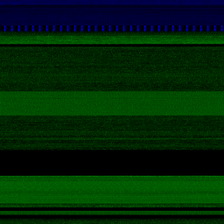

In [ ]:
import os
from pathlib import Path
from PIL import Image

TEST_ROOT = (
    "/content/gdrive/MyDrive/Malicious project work/"
    "Byteplot images/Image/test"
)

TRUE_LABEL = "riskware"
class_dir = os.path.join(TEST_ROOT, TRUE_LABEL)

image_files = sorted(
    f for f in os.listdir(class_dir)
    if f.lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".webp"))
)

assert image_files, f"No test images found in {class_dir}"

image_path = os.path.join(class_dir, image_files[0])

with Image.open(image_path) as img:
    print("Selected image:", image_files[0])
    print("True label (evaluation only):", TRUE_LABEL)
    print("Image size:", img.size)
    display(img.copy().resize((224, 224)))

In [ ]:
results = run_detectors(image_path=image_path)

print("REAL TEST-IMAGE PREDICTIONS")
for result in results:
    print(result)

REAL TEST-IMAGE PREDICTIONS
{'model': 'mobilenet', 'status': 'error', 'message': "name 'vision_tool' is not defined"}
{'model': 'resnet', 'status': 'error', 'message': "name 'vision_tool' is not defined"}


In [ ]:
import torch
import numpy as np
from PIL import Image

def vision_tool(model_name, image_path):
    if model_name not in vision_models:
        raise ValueError(f"Model not loaded: {model_name}")

    # Use the preprocessing transform already defined earlier.
    image = Image.open(image_path).convert("RGB")
    tensor = image_transform(image).unsqueeze(0).to(DEVICE)

    model = vision_models[model_name]

    model.eval()
    with torch.inference_mode():
        logits = model(tensor)
        probabilities = torch.softmax(logits, dim=1)[0].cpu().numpy()

    class_labels = list(CLASS_NAMES)

    if len(probabilities) != len(class_labels):
        raise ValueError(
            f"{model_name} has {len(probabilities)} outputs, "
            f"but CLASS_NAMES has {len(class_labels)} labels."
        )

    index = int(np.argmax(probabilities))

    return {
        "model": model_name,
        "predicted_class": class_labels[index],
        "confidence": round(float(probabilities[index]), 4),
        "probabilities": {
            label: round(float(prob), 4)
            for label, prob in zip(class_labels, probabilities)
        }
    }

In [ ]:
results = run_detectors(image_path=image_path)

for result in results:
    print(result)

{'model': 'mobilenet', 'status': 'error', 'message': "name 'image_transform' is not defined"}
{'model': 'resnet', 'status': 'error', 'message': "name 'image_transform' is not defined"}


In [ ]:
from torchvision import transforms

image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image transform defined.")

Image transform defined.


In [ ]:
results = run_detectors(image_path=image_path)

for result in results:
    print(result)

{'model': 'mobilenet', 'status': 'error', 'message': "name 'CLASS_NAMES' is not defined"}
{'model': 'resnet', 'status': 'error', 'message': "name 'CLASS_NAMES' is not defined"}


In [ ]:
import os
import numpy as np
import torch
from PIL import Image
from torchvision import transforms

# 1. Shared configuration
PROJECT_ROOT = "/content/gdrive/MyDrive/Malicious project work"
TEST_ROOT = os.path.join(PROJECT_ROOT, "Byteplot images", "Image", "test")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. Resolve class names without guessing their order
if "class_names" in globals() and class_names:
    CLASS_NAMES = list(class_names)
elif os.path.isdir(TEST_ROOT):
    # torchvision ImageFolder uses alphabetical class ordering by default.
    CLASS_NAMES = sorted(
        d for d in os.listdir(TEST_ROOT)
        if os.path.isdir(os.path.join(TEST_ROOT, d))
    )
else:
    raise RuntimeError(
        "Cannot determine class names. Check the saved training metadata."
    )

# 3. Image preprocessing
# Standard ImageNet preprocessing; replace if your training pipeline differed.
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# 4. Image inference function
def vision_tool(model_name, image_path):
    if "vision_models" not in globals():
        raise RuntimeError("vision_models is not defined in this runtime.")
    if model_name not in vision_models:
        raise RuntimeError(f"{model_name} is not loaded.")
    if not os.path.isfile(image_path):
        raise FileNotFoundError(image_path)

    image = Image.open(image_path).convert("RGB")
    inputs = image_transform(image).unsqueeze(0).to(DEVICE)

    detector = vision_models[model_name]
    detector.eval()

    with torch.inference_mode():
        logits = detector(inputs)
        probs = torch.softmax(logits, dim=1)[0].cpu().numpy()

    if len(probs) != len(CLASS_NAMES):
        raise ValueError(
            f"{model_name} outputs {len(probs)} classes, but "
            f"CLASS_NAMES contains {len(CLASS_NAMES)}: {CLASS_NAMES}"
        )

    idx = int(np.argmax(probs))
    return {
        "model": model_name,
        "status": "success",
        "predicted_class": CLASS_NAMES[idx],
        "confidence": round(float(probs[idx]), 4),
        "probabilities": {
            label: round(float(p), 4)
            for label, p in zip(CLASS_NAMES, probs)
        }
    }

# 5. CNN-BiLSTM wrapper, if its earlier function was lost
if "bilstm_tool" not in globals() and all(
    name in globals() for name in ("model", "vocab", "MAX_LEN", "device")
):
    # Avoid using a model variable that might refer to Qwen.
    print("BiLSTM wrapper not recreated: model reference must be identified safely.")

# 6. Coordinator
def run_detectors(image_path=None, api_sequence=None, lgbm_features=None):
    results = []

    if image_path is not None:
        for name in ("mobilenet", "resnet"):
            try:
                results.append(vision_tool(name, image_path))
            except Exception as e:
                results.append({
                    "model": name,
                    "status": "error",
                    "message": str(e)
                })

    if api_sequence is not None:
        if "bilstm_tool" in globals():
            try:
                results.append(bilstm_tool(api_sequence))
            except Exception as e:
                results.append({
                    "model": "CNN-BiLSTM",
                    "status": "error",
                    "message": str(e)
                })
        else:
            results.append({
                "model": "CNN-BiLSTM",
                "status": "unavailable",
                "message": "bilstm_tool is not defined."
            })

    if lgbm_features is not None:
        if "lightgbm_tool" in globals():
            try:
                results.append(lightgbm_tool(lgbm_features))
            except Exception as e:
                results.append({
                    "model": "LightGBM",
                    "status": "error",
                    "message": str(e)
                })
        else:
            results.append({
                "model": "LightGBM",
                "status": "unavailable",
                "message": "lightgbm_tool is not defined."
            })

    return results

print("Shared setup complete.")
print("Device:", DEVICE)
print("Classes:", CLASS_NAMES)
print("MobileNetV3 loaded:", "mobilenet" in globals().get("vision_models", {}))
print("ResNet50 loaded:", "resnet" in globals().get("vision_models", {}))
print("BiLSTM tool defined:", callable(globals().get("bilstm_tool")))
print("LightGBM tool defined:", callable(globals().get("lightgbm_tool")))
print("Qwen report defined:", callable(globals().get("qwen_malware_report")))

Shared setup complete.
Device: cuda
Classes: ['adware', 'banking', 'benign', 'riskware', 'sms']
MobileNetV3 loaded: True
ResNet50 loaded: True
BiLSTM tool defined: True
LightGBM tool defined: True
Qwen report defined: True


In [ ]:
results = run_detectors(image_path=image_path)

for result in results:
    print(result)

{'model': 'mobilenet', 'status': 'success', 'predicted_class': 'benign', 'confidence': 0.9993, 'probabilities': {'adware': 0.0, 'banking': 0.0003, 'benign': 0.9993, 'riskware': 0.0004, 'sms': 0.0}}
{'model': 'resnet', 'status': 'success', 'predicted_class': 'benign', 'confidence': 0.9976, 'probabilities': {'adware': 0.0001, 'banking': 0.0016, 'benign': 0.9976, 'riskware': 0.0006, 'sms': 0.0001}}


In [ ]:

import json
import re
import torch

def qwen_malware_report(detector_outputs):
    prompt = f"""
You are a malware-analysis reporting assistant.

Use only the detector outputs provided below.
Do not invent predictions, evidence, or confidence values.
Do not treat agreement between models as proof of correctness.
If evidence is insufficient, state that clearly.

Return one complete JSON object with exactly these keys:
- verdict
- supporting_predictions
- unavailable_models
- limitations
- explanation

Allowed verdicts: "malicious", "benign", "uncertain".

Detector outputs:
{json.dumps(detector_outputs, ensure_ascii=False)}

Return JSON only. Do not use Markdown fences.
Keep the explanation concise.
"""

    messages = [
        {
            "role": "user",
            "content": prompt
        }
    ]

    inputs = qwen_tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    )

    # Place inputs on the model's input device.
    input_device = qwen_model.get_input_embeddings().weight.device
    inputs = {k: v.to(input_device) for k, v in inputs.items()}

    with torch.no_grad():
        output = qwen_model.generate(
            **inputs,
            max_new_tokens=500,
            do_sample=False,
            pad_token_id=qwen_tokenizer.eos_token_id,
            eos_token_id=qwen_tokenizer.eos_token_id
        )

    # Decode only newly generated tokens.
    generated_tokens = output[0][inputs["input_ids"].shape[1]:]
    answer = qwen_tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    ).strip()

    # Remove optional Markdown fences.
    cleaned = re.sub(r"^\s*```(?:json)?\s*", "", answer, flags=re.IGNORECASE)
    cleaned = re.sub(r"\s*```\s*$", "", cleaned)

    # Extract the JSON object.
    start = cleaned.find("{")
    end = cleaned.rfind("}")

    if start == -1 or end <= start:
        return {
            "error": "No complete JSON object returned",
            "raw_response": answer
        }

    try:
        report = json.loads(cleaned[start:end + 1])
    except json.JSONDecodeError as e:
        return {
            "error": f"Invalid or incomplete JSON: {e}",
            "raw_response": answer
        }

    required_keys = {
        "verdict",
        "supporting_predictions",
        "unavailable_models",
        "limitations",
        "explanation"
    }

    if not required_keys.issubset(report):
        return {
            "error": "JSON is missing required fields",
            "missing_keys": sorted(required_keys - set(report)),
            "parsed_response": report
        }

    return report


In [ ]:
report_input = {
    "analysis_type": "byteplot_test_inference",
    "detectors": results,
    "unavailable_models": [
        "LightGBM — feature vector not supplied",
        "CNN-BiLSTM — API-call sequence not supplied"
    ],
    "limitations": [
        "Only two image models were run.",
        "This is a test-dataset image, not a complete APK analysis."
    ]
}

report = qwen_malware_report(report_input)
print(json.dumps(report, indent=2, ensure_ascii=False))

{
  "verdict": "benign",
  "supporting_predictions": [
    {
      "model": "mobilenet",
      "predicted_class": "benign",
      "confidence": 0.9993
    },
    {
      "model": "resnet",
      "predicted_class": "benign",
      "confidence": 0.9976
    }
  ],
  "unavailable_models": [
    "LightGBM — feature vector not supplied",
    "CNN-BiLSTM — API-call sequence not supplied"
  ],
  "limitations": [
    "Only two image models were run.",
    "This is a test-dataset image, not a complete APK analysis."
  ],
  "explanation": "The analysis was based on two image models which both predicted the sample as benign with high confidence. However, due to the limitations mentioned, this conclusion may not be definitive for a full APK analysis."
}


In [ ]:
print("Dataset class names:", CLASS_NAMES)

for name, model_obj in vision_models.items():
    print(f"\n{name}:")
    print("Model type:", type(model_obj).__name__)

    if hasattr(model_obj, "classifier"):
        print("Classifier:", model_obj.classifier)
    elif hasattr(model_obj, "fc"):
        print("Final layer:", model_obj.fc)

Dataset class names: ['adware', 'banking', 'benign', 'riskware', 'sms']

mobilenet:
Model type: MobileNetV3
Classifier: Sequential(
  (0): Linear(in_features=960, out_features=1280, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1280, out_features=5, bias=True)
)

resnet:
Model type: ResNet
Final layer: Linear(in_features=2048, out_features=5, bias=True)


In [ ]:

import os
import random
import pandas as pd
from PIL import Image

# Uses the existing models and inference function.
# Ground-truth labels are used only for evaluation, never as model input.
random.seed(42)

rows = []

for true_label in CLASS_NAMES:
    class_dir = os.path.join(TEST_ROOT, true_label)
    files = sorted(
        f for f in os.listdir(class_dir)
        if f.lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".webp"))
    )

    if not files:
        print(f"No images found for {true_label}")
        continue

    chosen = random.sample(files, min(10, len(files)))

    for filename in chosen:
        image_path = os.path.join(class_dir, filename)

        for model_name in ("mobilenet", "resnet"):
            result = vision_tool(model_name, image_path)

            rows.append({
                "true_label": true_label,
                "model": model_name,
                "predicted_label": result.get("predicted_class"),
                "confidence": result.get("confidence"),
                "correct": result.get("predicted_class") == true_label,
                "filename": filename
            })

evaluation_df = pd.DataFrame(rows)

print("Images evaluated:", evaluation_df["filename"].nunique())
print("\nAccuracy by model:")
print(
    evaluation_df.groupby("model")["correct"]
    .mean().mul(100).round(2).astype(str).add("%")
)

print("\nAccuracy by true class and model:")
print(
    evaluation_df.pivot_table(
        index="true_label",
        columns="model",
        values="correct",
        aggfunc="mean"
    ).mul(100).round(2)
)

display(evaluation_df.head(15))


Images evaluated: 50

Accuracy by model:
model
mobilenet    96.0%
resnet       98.0%
Name: correct, dtype: object

Accuracy by true class and model:
model       mobilenet  resnet
true_label                   
adware          100.0   100.0
banking          80.0    90.0
benign          100.0   100.0
riskware        100.0   100.0
sms             100.0   100.0


,true_label,model,predicted_label,confidence,correct,filename
0,adware,mobilenet,adware,0.9697,True,b8cf2e3cc7c40d693ccb1deba2111327d55317b4d59ff4...
1,adware,resnet,adware,0.9999,True,b8cf2e3cc7c40d693ccb1deba2111327d55317b4d59ff4...
2,adware,mobilenet,adware,0.9998,True,1eec524aaba93bcdeda0cdaa7e20fea8b917e1410391bd...
3,adware,resnet,adware,0.9998,True,1eec524aaba93bcdeda0cdaa7e20fea8b917e1410391bd...
4,adware,mobilenet,adware,0.9874,True,075049984d2937039dde452818bc6b844c8c8cd17232db...
5,adware,resnet,adware,0.9980,True,075049984d2937039dde452818bc6b844c8c8cd17232db...
6,adware,mobilenet,adware,0.9997,True,d61d7b79c4af714cae502271c5059ce09d8759a47219ff...
7,adware,resnet,adware,1.0000,True,d61d7b79c4af714cae502271c5059ce09d8759a47219ff...
8,adware,mobilenet,adware,0.9992,True,522d9630bbfd2599eaee00d2b0f29e239865abc53c1f30...
9,adware,resnet,adware,0.9996,True,522d9630bbfd2599eaee00d2b0f29e239865abc53c1f30...
